In [1]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnableParallel

llm_openai = ChatOpenAI(model="gpt-5-mini", temperature=0)

llms are not trained on our data
If we want to train llm based on our data we need TOOLS

# **TOOLS**

In [21]:
#Tool 1 [DuckDuckGo]
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper
from langchain_core.tools import tool

# LangChain defaults to region="wt-wt". ddgs treats the suffix as a Wikipedia
# language code, so it queries wt.wikipedia.org (no DNS records).
search_tool = DuckDuckGoSearchRun(
    api_wrapper=DuckDuckGoSearchAPIWrapper(region="us-en")
)


#Tool 2 [Wikipedia Search Tool]
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

wikipedia_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(), description="This is a tool to serach wikipedia")

#Tool 3 [Custom Enterprise Tool]
from langchain_community.tools import Tool

@tool
def enterprise_tool(qyery: str) -> str:
    """ This is a tool to send emails to employees
     """
    return "Email sent"






# **Toolkit**

In [14]:
Toolkit = [search_tool, wikipedia_tool, enterprise_tool]

In [15]:
Toolkit

[DuckDuckGoSearchRun(api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(description='This is a tool to serach wikipedia', api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from '/Users/c.caravaggio/Desktop/Progetti/LangChainTest/.venv/lib/python3.14/site-packages/wikipedia/__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_tool', description='This is a tool to send emails to employees', args_schema=<class 'langchain_core.utils.pydantic.enterprise_tool'>, func=<function enterprise_tool at 0x1154354e0>)]

# **ReAct agent**

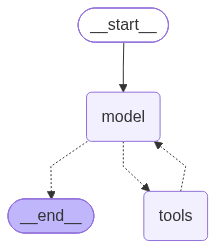

In [17]:
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

agent = create_agent(model="openai:gpt-5-mini", tools=Toolkit)
agent

# **React agent invoke with streams**

In [23]:
example_query = "Give me the latest news about the stock market"

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Give me the latest news about the stock market
================================== Ai Message ==================================
Tool Calls:
  duckduckgo_search (call_xr3lseP2SkC7sti3PP8s8SDK)
 Call ID: call_xr3lseP2SkC7sti3PP8s8SDK
  Args:
    query: stock market latest news today
================================= Tool Message =================================
Name: duckduckgo_search

The Last Stock Jumped 350%! Read More About the Future of America's Economy and How It Is Going to Move Forward. Content Types, Investment Strategies, Stock Analysis, Financial Reports and more 12 hours ago · Find the latest stock market news from every corner of the globe at Reuters.com, your online source for breaking international market and finance news MarketWatch provides the latest stock market, financial and business news. Get stock market quotes, personal finance advice, company news and more. At Yahoo Finance, you 

# **Manually Binding LLM with tools**

In [26]:
# Without binding
llm_openai.invoke("Give me the latest news about the stock market")

AIMessage(content='I don’t have live internet access, so I can’t pull today’s market headlines. My training data goes through June 2024, and I can’t see events after that. I can, however:\n\n- Give a short market snapshot of persistent themes through mid‑2024.\n- Explain how to get reliable, real‑time market news and tickers.\n- Summarize or analyze any news/articles you paste or links you provide.\n- Prepare a template you can use each day to check the market quickly.\n\nQuick summary of major themes through mid‑2024\n- Central banks and rates: Markets were focused on inflation data and central bank policy. Investors were watching whether major central banks would pivot from the tight monetary stance and when rate cuts might begin.\n- AI and big-cap tech: AI-related companies (notably large semiconductor and cloud names) were key drivers of indexes, and large-cap tech performance often dominated index returns.\n- Earnings and guidance: Quarterly earnings beats/misses and guidance cont

In [25]:
# With binding
llm_binded = llm_openai.bind_tools(Toolkit)
llm_binded.invoke("Give me the latest news about the stock market")

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 163, 'prompt_tokens': 219, 'total_tokens': 382, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 128, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EduKC0n0eHCx0kf1RJkJpmTDd6rEV', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a181db-8c1a-7351-ae52-55aca9a4b9a2-0', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': 'stock market news today October 28 2026'}, 'id': 'call_m2mf8H0SvKzppipX7CYD5iOG', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 219, 'output_tokens': 163, 'total_tokens': 